# IMPORT

In [245]:
import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

import matplotlib.pyplot as plt


# DEFINE FOLDERS

In [246]:
STATION_FEATURE_FOLDER = Path("station_features")
STATION_CLUSTER_FOLDER = Path("station_clusters")
CLUSTER_SUMMARY_FOLDER = Path("cluster_summary")
CLUSTER_PLOT_FOLDER = Path("cluster_plot")

folders = [STATION_FEATURE_FOLDER, STATION_CLUSTER_FOLDER, CLUSTER_SUMMARY_FOLDER, CLUSTER_PLOT_FOLDER]
for folder in folders:
    folder.mkdir(parents=True, exist_ok=True)

# LOAD DATA

In [247]:
df = pd.read_csv(f"{STATION_FEATURE_FOLDER}/station_features.csv")

print("Stations:", df.shape[0])

Stations: 1474


# SELECT FEATURES FOR CLUSTERING

In [248]:
"""
exclude:
-stationcode
-latitude / longitude (for now)
-capacity (size != behavior)
"""

cluster_features = [
    "mean_usage",
    "std_usage",
    "daily_amplitude",
    "mean_weekend",
    "mean_weekday",
    "day_usage",
    "night_usage",
    "corr_weather_temperature_2m",
    "corr_weather_wind_speed_10m",
    "corr_weather_wind_direction_10m",
    "corr_weather_weather_code",
]

# Keep only existing columns (safety)
cluster_features = [c for c in cluster_features if c in df.columns]

X = df[cluster_features]
print("Clustering features:", cluster_features)

Clustering features: ['mean_usage', 'std_usage', 'daily_amplitude', 'mean_weekend', 'mean_weekday', 'day_usage', 'night_usage', 'corr_weather_temperature_2m', 'corr_weather_wind_speed_10m', 'corr_weather_wind_direction_10m', 'corr_weather_weather_code']


# SCALE FEATURES

In [249]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# CHOOSE NUMBER OF CLUSTERS (ELBOW METHOD)

c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning:

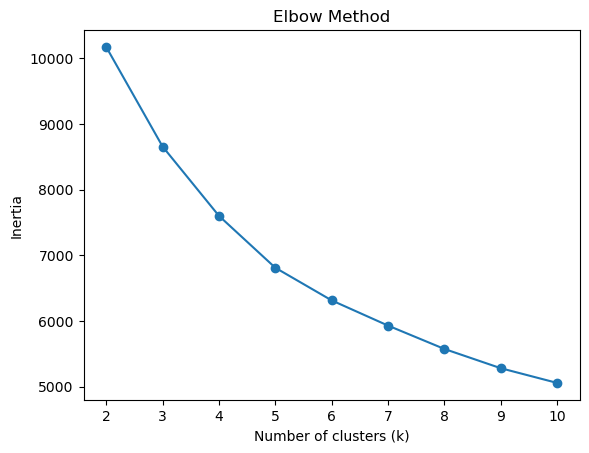

In [250]:
inertias = []
K_range = range(2, 11)
random_state = 42

for k in K_range:
    km = KMeans(n_clusters=k, random_state=random_state, n_init=20)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.figure()
plt.plot(K_range, inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()


# CHOOSE NUMBER OF CLUSTERS (SILHOUETTE SCORE)

In [251]:

for k in range(2, 8):
    km = KMeans(n_clusters=k, random_state=random_state, n_init=20)
    labels = km.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    print(f"k={k} → silhouette={score:.3f}")


c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


k=2 → silhouette=0.337
k=3 → silhouette=0.312


c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


k=4 → silhouette=0.299


c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


k=5 → silhouette=0.300


c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


k=6 → silhouette=0.203


c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


k=7 → silhouette=0.199


# FINAL CLUSTERING

In [ ]:
K = 2 # Should be choosen after seeing the plot etc

kmeans = KMeans(n_clusters=K, random_state=random_state, n_init=50)
df["cluster"] = kmeans.fit_predict(X_scaled)

print(df["cluster"].value_counts())


c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


cluster
1    660
0    248
2    219
3    175
4    172
Name: count, dtype: int64


# SAVE STATION -> CLUSTER MAPPING

In [253]:
df[["stationcode", "cluster"]].to_csv(
    F"{STATION_CLUSTER_FOLDER}/station_clusters_{K}_{random_state}.csv", index=False
)

print(f"✅ Saved {STATION_CLUSTER_FOLDER}/station_clusters_{K}_{random_state}.csv")

✅ Saved station_clusters/station_clusters_5_42.csv


# UNDERSTANDING WHAT EACH CLUSTER MEANS

In [254]:
cluster_summary = (
    df.groupby("cluster")[cluster_features]
    .mean()
    .round(3)
)

cluster_summary.to_csv(f"{CLUSTER_SUMMARY_FOLDER}/cluster_summary_{K}_{random_state}.csv")
print(cluster_summary)

         mean_usage  std_usage  daily_amplitude  mean_weekend  mean_weekday  \
cluster                                                                       
0             0.615      0.224            0.239         0.632         0.609   
1             0.228      0.173            0.226         0.238         0.224   
2             0.448      0.282            0.479         0.398         0.468   
3             0.555      0.221            0.195         0.564         0.551   
4             0.474      0.266            0.466         0.501         0.464   

         day_usage  night_usage  corr_weather_temperature_2m  \
cluster                                                        
0            0.613        0.616                       -0.138   
1            0.197        0.246                       -0.068   
2            0.603        0.357                        0.115   
3            0.562        0.550                        0.128   
4            0.325        0.562                       -0.133  

# VISUAL CHECK

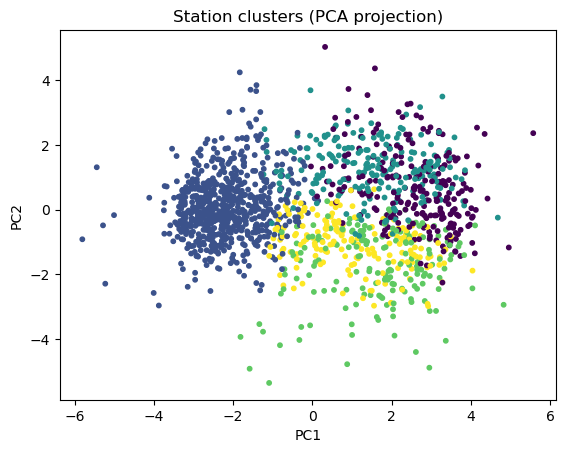

In [255]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure()
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df["cluster"], s=10)
plt.title("Station clusters (PCA projection)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.savefig(f"{CLUSTER_PLOT_FOLDER}/station_clusters_pca_{K}_{random_state}.png", dpi=300, bbox_inches='tight')
plt.show()
